Descargando dataset IMDb...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total entrenamiento: 25000 | Total prueba: 25000
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Vocabulario guardado como 'word_index.json'


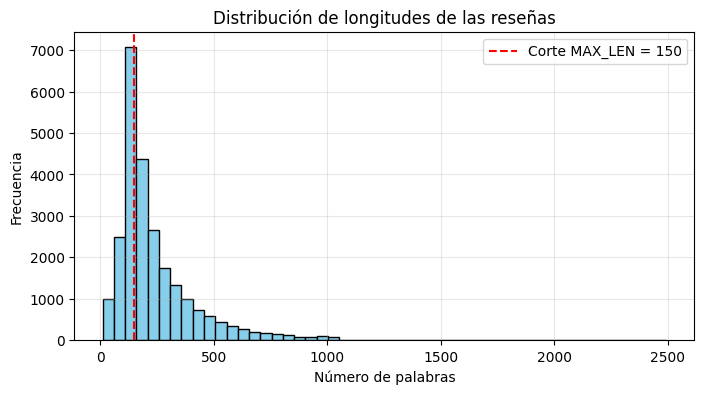

Forma X_train: (20000, 150) | X_val: (5000, 150) | X_test: (25000, 150)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 710,209 (2.71 MB)

 Trainable params: 710,209 (2.71 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 72s 424ms/step - accuracy: 0.6525 - loss: 0.6068 - val_accuracy: 0.8160 - val_loss: 0.4229
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 66s 423ms/step - accuracy: 0.8522 - loss: 0.3645 - val_accuracy: 0.8452 - val_loss: 0.3715
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 70s 444ms/step - accuracy: 0.9030 - loss: 0.2596 - val_accuracy: 0.8446 - val_loss: 0.4034
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 65s 413ms/step - accuracy: 0.9195 - loss: 0.2236 - val_accuracy: 0.8278 - val_loss: 0.5730
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 65s 414ms/step - accuracy: 0.9283 - loss: 0.1982 - val_accuracy: 0.8394 - val_loss: 0.4665


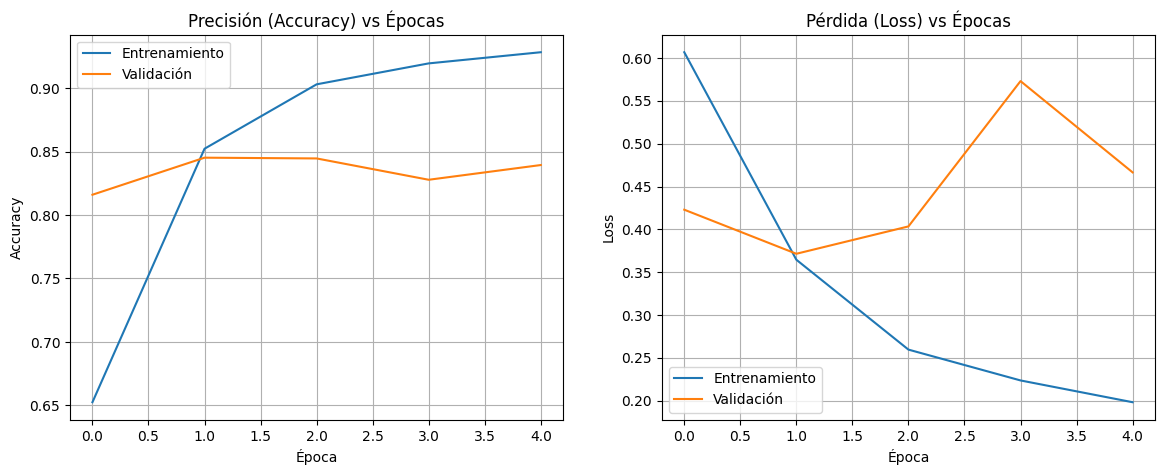


Exactitud global en Test: 83.46%
782/782 ━━━━━━━━━━━━━━━━━━━━ 27s 35ms/step

Reporte de Clasificación:
              precision    recall  f1-score   support

    Negativo       0.83      0.85      0.84     12500
    Positivo       0.84      0.82      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



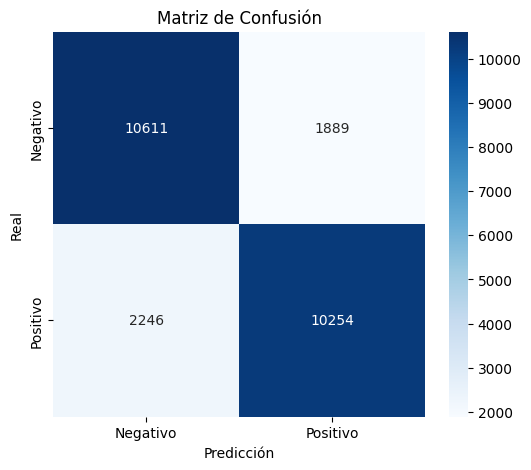


=== MUESTRA DE 10 PREDICCIONES ===
[1] Real: Negativo | Predicho: Negativo | Confianza: 97.29%
     Texto: "please give this one a miss br br and the rest of the cast rendered terrible performances ..."

[2] Real: Positivo | Predicho: Positivo | Confianza: 95.05%
     Texto: "this film requires a lot of patience because it focuses on mood and character development ..."

[3] Real: Positivo | Predicho: Positivo | Confianza: 92.07%
     Texto: "many animation buffs consider the great forgotten genius of one special branch of the art ..."

[4] Real: Negativo | Predicho: Negativo | Confianza: 90.82%
     Texto: "i generally love this type of movie however this time i found myself wanting to kick the s..."

[5] Real: Positivo | Predicho: Positivo | Confianza: 93.33%
     Texto: "like some other people wrote i'm a die hard mario fan and i loved this game br br this gam..."

[6] Real: Positivo | Predicho: Negativo | Confianza: 93.90%
     Texto: "i'm absolutely disgusted this movie isn't bein

In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing import sequence

tf.random.set_seed(42)
np.random.seed(42)

VOCAB_SIZE = 10000
MAX_LEN = 150

print("Descargando dataset IMDb...")
(X_train_full, y_train_full), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

class_names = ['Negativo', 'Positivo']
print(f"Total entrenamiento: {len(X_train_full)} | Total prueba: {len(X_test)}")

word_to_id = imdb.get_word_index()
word_to_id = {k: (v + 3) for k, v in word_to_id.items() if (v + 3) < VOCAB_SIZE}
word_to_id["<PAD>"] = 0
word_to_id["<START>"] = 1
word_to_id["<UNK>"] = 2

with open("word_index.json", "w", encoding="utf-8") as f:
    json.dump(word_to_id, f)
print("Vocabulario guardado como 'word_index.json'")

lengths = [len(seq) for seq in X_train_full]
plt.figure(figsize=(8, 4))
plt.hist(lengths, bins=50, color='skyblue', edgecolor='black')
plt.axvline(MAX_LEN, color='red', linestyle='--', label=f'Corte MAX_LEN = {MAX_LEN}')
plt.title('Distribución de longitudes de las reseñas')
plt.xlabel('Número de palabras')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

X_train_pad = sequence.pad_sequences(X_train_full, maxlen=MAX_LEN, padding='post', truncating='post')
X_test_pad = sequence.pad_sequences(X_test, maxlen=MAX_LEN, padding='post', truncating='post')

val_split = int(len(X_train_pad) * 0.8)
X_train, X_val = X_train_pad[:val_split], X_train_pad[val_split:]
y_train, y_val = y_train_full[:val_split], y_train_full[val_split:]

print(f"Forma X_train: {X_train.shape} | X_val: {X_val.shape} | X_test: {X_test_pad.shape}")

model = models.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(input_dim=VOCAB_SIZE, output_dim=64),
    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
    layers.Dropout(0.4),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping]
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(history.history['accuracy'], label='Entrenamiento')
ax[0].plot(history.history['val_accuracy'], label='Validación')
ax[0].set_title('Precisión (Accuracy) vs Épocas')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history.history['loss'], label='Entrenamiento')
ax[1].plot(history.history['val_loss'], label='Validación')
ax[1].set_title('Pérdida (Loss) vs Épocas')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Loss')
ax[1].legend()
ax[1].grid(True)
plt.show()

test_loss, test_acc = model.evaluate(X_test_pad, y_test, verbose=0)
print(f"\nExactitud global en Test: {test_acc * 100:.2f}%")

y_pred_probs = model.predict(X_test_pad)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred, target_names=class_names))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

id_to_word = {v: k for k, v in word_to_id.items()}

def decode_review(encoded_seq):
    return " ".join([id_to_word.get(idx, "?") for idx in encoded_seq if idx > 2])

print("\n=== MUESTRA DE 10 PREDICCIONES ===")
for i in range(10):
    review_snippet = decode_review(X_test[i])[:90] + "..."
    prob = y_pred_probs[i][0]
    pred_label = "Positivo" if prob >= 0.5 else "Negativo"
    real_label = "Positivo" if y_test[i] == 1 else "Negativo"
    print(f"[{i+1}] Real: {real_label:<8} | Predicho: {pred_label:<8} | Confianza: {prob*100 if prob>=0.5 else (1-prob)*100:.2f}%")
    print(f"     Texto: \"{review_snippet}\"\n")

model.save("modelo_lstm.keras")
print("Modelo guardado como 'modelo_lstm.keras'")